<a href="https://colab.research.google.com/github/group6aiml-hub/NIDS_AInML/blob/main/notebooks/01_explore.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
import os
import numpy as np
import pandas as pd
print(os.listdir('/content'))
print(os.listdir('/content/drive'))
print(os.listdir('/content/drive/MyDrive'))

['.config', 'drive', 'sample_data']
['.shortcut-targets-by-id', 'MyDrive', '.Trash-0', '.Encrypted']
['Datasets', '03_baseline.ipynb', '04_multiclass.ipynb', '05_imbalance.ipynb', '06_feature_selection.ipynb', '07_BaselineComparison.ipynb', '07_template.ipynb', '02_cleaning.ipynb']


In [3]:
path = '/content/drive/MyDrive/Datasets/'
print(os.listdir(path))   # check that both CSVs show up

train = pd.read_csv(path + 'UNSW_NB15_training-set.csv', encoding='utf-8-sig')
test  = pd.read_csv(path + 'UNSW_NB15_testing-set.csv',  encoding='utf-8-sig')
print(train.shape, test.shape)

['UNSW_NB15_testing-set.csv', 'UNSW_NB15_training-set.csv', '01_explore.ipynb', 'train_clean.csv', 'test_clean.csv', 'resultater_imbalance.csv']
(175341, 45) (82332, 45)


In [4]:
train.info()
train.head()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 175341 entries, 0 to 175340
Data columns (total 45 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   id                 175341 non-null  int64  
 1   dur                175341 non-null  float64
 2   proto              175341 non-null  object 
 3   service            175341 non-null  object 
 4   state              175341 non-null  object 
 5   spkts              175341 non-null  int64  
 6   dpkts              175341 non-null  int64  
 7   sbytes             175341 non-null  int64  
 8   dbytes             175341 non-null  int64  
 9   rate               175341 non-null  float64
 10  sttl               175341 non-null  int64  
 11  dttl               175341 non-null  int64  
 12  sload              175341 non-null  float64
 13  dload              175341 non-null  float64
 14  sloss              175341 non-null  int64  
 15  dloss              175341 non-null  int64  
 16  si

,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,...,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.121478,tcp,-,FIN,6,4,258,172,74.087490,...,1,1,0,0,0,1,1,0,Normal,0
1,2,0.649902,tcp,-,FIN,14,38,734,42014,78.473372,...,1,2,0,0,0,1,6,0,Normal,0
2,3,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,...,1,3,0,0,0,2,6,0,Normal,0
3,4,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,...,1,3,1,1,0,2,1,0,Normal,0
4,5,0.449454,tcp,-,FIN,10,6,534,268,33.373826,...,1,40,0,0,0,2,39,0,Normal,0


In [5]:
train['label'].value_counts(normalize=True)


,proportion
label,
1,0.680622
0,0.319378


In [6]:
train['attack_cat'].value_counts(normalize=True)


,proportion
attack_cat,
Normal,0.319378
Generic,0.228127
Exploits,0.190446
Fuzzers,0.103706
DoS,0.069944
Reconnaissance,0.059832
Analysis,0.011406
Backdoor,0.009958
Shellcode,0.006462


In [7]:
train['attack_cat'].duplicated().sum()

np.int64(175331)

<Axes: >

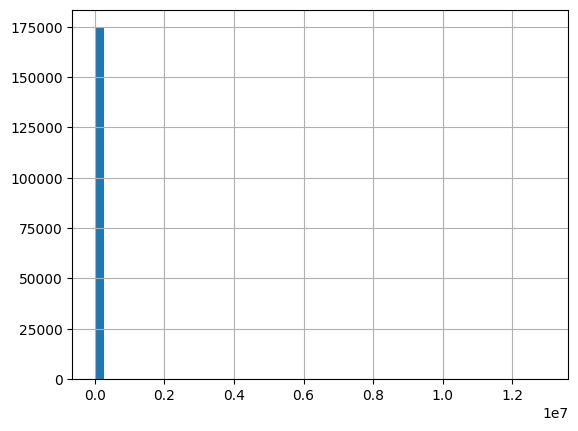

In [8]:
train['sbytes'].hist(bins=50)


<Axes: >

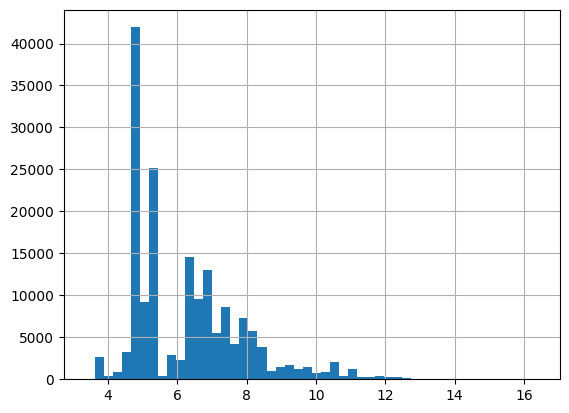

In [9]:
np.log1p(train['sbytes']).hist(bins=50)

<Axes: >

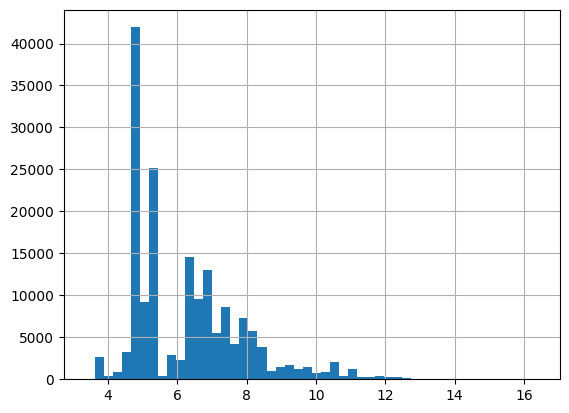

In [10]:

np.log1p(train['sbytes']).hist(bins=50)

In [11]:
train.select_dtypes('number').skew().sort_values(ascending=False)


,0
trans_depth,167.335829
response_body_len,76.340075
sbytes,45.303443
sloss,44.753662
dloss,41.380270
spkts,40.217703
dbytes,39.760864
dpkts,36.764114
dinpkt,29.679512
djit,29.543830
